# Number of trajectories reaching a given trajectory length (Plain MD, EE)

The Plain MD and EE data come from Folding@Home, so individual trajectories have different lengths.
The population-over-time curves (`population_over_time_*_all.ipynb`) average each trajectory's running
population over the trajectories that are still running at time $t$, so fewer trajectories contribute at
long times. This notebook plots $N(t)$, the number of trajectories whose length is at least $t$, using the
same trajectory sets as the population analysis:

- **Plain MD**: the first 754 trajectories of `Plain_MD/analysis/omega_data/data.pkl`, as in
  `Plain_MD/analysis/cistrans_population.ipynb` (`res_all_traj[:, :754, :]`).
- **EE**: all trajectories in `EE/analysis/omega_data/all_omega.pkl`.

Both are saved every 10 ps.

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import pickle

In [2]:
class Data:
    def __init__(self, array_list):
        self.array_list = array_list

    def save(self, filename):
        with open(filename, 'wb') as f:
            pickle.dump(self.array_list, f)

    @classmethod
    def load(cls, filename):
        with open(filename, 'rb') as f:
            array_list = pickle.load(f)
        return cls(array_list)

## Load trajectory lengths

In [3]:
dt_in_ns = 0.01  # 10 ps per frame for both Plain MD and EE

plain_md_path = '../Plain_MD/analysis'
plain_md_omega = Data.load(f"{plain_md_path}/omega_data/data.pkl").array_list
plain_md_omega = plain_md_omega[:754]  # same subset used for population over time
plain_md_lengths_ns = np.array([len(traj) for traj in plain_md_omega]) * dt_in_ns

ee_path = '../EE/analysis'
ee_omega = Data.load(f"{ee_path}/omega_data/all_omega.pkl").array_list
ee_lengths_ns = np.array([len(traj) for traj in ee_omega]) * dt_in_ns

for name, lengths in [('Plain MD', plain_md_lengths_ns), ('EE', ee_lengths_ns)]:
    print(f"{name}: {len(lengths)} trajectories, "
          f"min {lengths.min():.0f} ns, median {np.median(lengths):.0f} ns, "
          f"max {lengths.max():.0f} ns, aggregate {lengths.sum():.0f} ns")

Plain MD: 754 trajectories, min 40 ns, median 1261 ns, max 4923 ns, aggregate 1080628 ns
EE: 100 trajectories, min 1710 ns, median 2365 ns, max 3180 ns, aggregate 240182 ns


## Plot $N(t)$

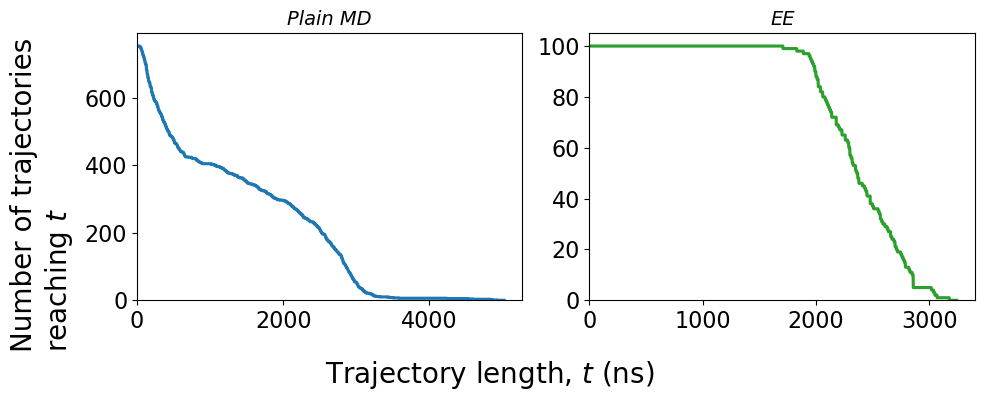

In [4]:
from plotting_style import (METHOD_COLORS, TICK_FONTSIZE, AXIS_LABEL_FONTSIZE,
                            LINEWIDTH, style_panel)


def n_traj_reaching(lengths_ns, time_ns):
    """Number of trajectories whose length is at least each value in time_ns."""
    sorted_lengths = np.sort(lengths_ns)
    return len(sorted_lengths) - np.searchsorted(sorted_lengths, time_ns, side='left')


datasets = [
    {'label': 'Plain MD', 'lengths': plain_md_lengths_ns},
    {'label': 'EE', 'lengths': ee_lengths_ns},
]

fig, axes = plt.subplots(1, len(datasets), figsize=(10, 4))
for ax, data in zip(axes, datasets):
    lengths = data['lengths']
    time_ns = np.linspace(0, lengths.max() * 1.02, 2000)
    ax.plot(time_ns, n_traj_reaching(lengths, time_ns),
            color=METHOD_COLORS[data['label']], linewidth=LINEWIDTH * 1.5)
    ax.set_xlim(0, None)
    ax.set_ylim(0, len(lengths) * 1.05)
    style_panel(ax, data['label'])

fig.supxlabel(r'Trajectory length, $t$ (ns)', fontsize=AXIS_LABEL_FONTSIZE)
fig.supylabel('Number of trajectories\nreaching $t$', fontsize=AXIS_LABEL_FONTSIZE)
plt.tight_layout()

savepath = 'SI_figure/SI_trajectory_length_count.pdf'
plt.savefig(savepath, dpi=300, bbox_inches='tight')
plt.show()